In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kevinigiraneza/country-school/Country Schools.csv


In [2]:
# Import pandas library
import pandas as pd

# Load the Country Schools dataset
df = pd.read_csv(
    '/kaggle/input/datasets/kevinigiraneza/country-school/Country Schools.csv'
)

# Display the first 5 rows
df.head()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [3]:

# Step 4: Understanding the Dataset

# Check the number of rows and columns
print("Dataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display information about the dataset
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape:
(50, 8)

Column Names:
Index(['SNO', 'TOTALSCHOOLS', 'TotalSchoolsInstalled', 'SchoolsPending',
       'PercentageInstalled', 'InstalledLDDs', 'InstalledTDDs', 'FID'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SNO                    48 non-null     object 
 1   TOTALSCHOOLS           48 non-null     float64
 2   TotalSchoolsInstalled  48 non-null     float64
 3   SchoolsPending         48 non-null     float64
 4   PercentageInstalled    48 non-null     object 
 5   InstalledLDDs          48 non-null     float64
 6   InstalledTDDs          48 non-null     float64
 7   FID                    50 non-null     int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 3.3+ KB

Missing Values:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstal

In [4]:

# Step 5: Data Preprocessing - Handling Missing Values

# Check the original number of rows
print("Original dataset shape:", df.shape)

# Remove rows where county names are missing
df_clean = df.dropna(subset=['SNO']).copy()

# Remove the TOTAL summary row
df_clean = df_clean[
    df_clean['SNO'].str.strip().str.upper() != 'TOTAL'
].copy()

# Reset the row index
df_clean.reset_index(drop=True, inplace=True)

# Display the cleaned dataset shape
print("Cleaned dataset shape:", df_clean.shape)

# Check for remaining missing values
print("\nRemaining missing values:")
print(df_clean.isnull().sum())


Original dataset shape: (50, 8)
Cleaned dataset shape: (47, 8)

Remaining missing values:
SNO                      0
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64


### Handling Missing Values

During data preprocessing, the dataset was checked for missing values using the `isnull().sum()` function.

The original dataset contained 50 rows and 8 columns. Two records with missing county information were removed. The TOTAL row was also excluded because it represents a summary rather than an individual county.

After cleaning, the dataset contained 47 rows and 8 columns, with no remaining missing values. This makes the dataset more suitable for anomaly detection and cluster analysis.

In [5]:

# Step 6: Convert PercentageInstalled to numerical data

# Remove the percentage symbol and convert to float
df_clean['PercentageInstalled'] = (
    df_clean['PercentageInstalled']
    .str.replace('%', '', regex=False)
    .astype(float)
)

# Check data types after conversion
print("Data types after conversion:")
print(df_clean.dtypes)

# Display the first five rows
print("\nFirst five rows after conversion:")
display(df_clean.head())


Data types after conversion:
SNO                       object
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled      float64
InstalledLDDs            float64
InstalledTDDs            float64
FID                        int64
dtype: object

First five rows after conversion:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5


### Converting Data Types

The PercentageInstalled column was initially stored as an object data type because its values contained percentage symbols (%).

During preprocessing, the percentage symbols were removed using the `str.replace()` function. The values were then converted into numerical format using `astype(float)`.

For example, 10.34% was converted to 10.34. This conversion is necessary because machine learning algorithms such as Isolation Forest and K-Means require numerical input for mathematical calculations.

In [6]:

# Step 7: Checking for Duplicate Records

# Check for completely duplicated rows
print("Total duplicate rows:")
print(df_clean.duplicated().sum())

# Check for duplicate county names
county_names = df_clean['SNO'].str.strip().str.upper()

print("\nDuplicate county names:")
print(county_names.duplicated().sum())

# Display duplicated county records, if any
print("\nDuplicate county records:")
display(df_clean[county_names.duplicated(keep=False)])

# Display dataset shape
print("\nDataset shape:", df_clean.shape)


Total duplicate rows:
0

Duplicate county names:
0

Duplicate county records:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID



Dataset shape: (47, 8)


### Checking for Duplicate Records

After handling missing values and converting data types, the dataset was checked for duplicate records using the `duplicated()` function in Pandas.

The results showed that there were no duplicate rows or duplicate county names in the cleaned dataset.

Therefore, no additional records needed to be removed. The dataset still contained 47 rows and 8 columns.

Checking for duplicates is important because repeated records can affect the accuracy of anomaly detection and cluster analysis.

In [7]:

# Step 8: Feature Selection and Data Standardization

# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Select features for machine learning
features = [
    'TOTALSCHOOLS',
    'PercentageInstalled',
    'InstalledLDDs'
]

# Create a dataset containing selected features
X = df_clean[features].copy()

# Display selected features
print("Selected Features:")
display(X.head())

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert standardized data into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

# Display standardized data
print("\nStandardized Data:")
display(X_scaled_df.head().round(2))

# Check the shape
print("\nStandardized dataset shape:", X_scaled.shape)


Selected Features:


,TOTALSCHOOLS,PercentageInstalled,InstalledLDDs
0,358.0,10.34,3744.0
1,875.0,63.09,22982.0
2,498.0,48.59,15114.0
3,1238.0,96.93,42162.0
4,159.0,89.94,7415.0



Standardized Data:


,TOTALSCHOOLS,PercentageInstalled,InstalledLDDs
0,-0.41,-2.10,-1.03
1,1.64,-0.03,0.67
2,0.14,-0.60,-0.02
3,3.08,1.29,2.36
4,-1.21,1.02,-0.70



Standardized dataset shape: (47, 3)


### Feature Selection and Data Standardization

After cleaning the dataset, three numerical features were selected for machine learning: TOTALSCHOOLS, PercentageInstalled, and InstalledLDDs.

These features were selected because they provide information about the number of schools, installation coverage, and installed LDDs in each county.

Data standardization was performed using StandardScaler from the Scikit-learn library. This method transforms numerical features to have a mean of approximately zero and a standard deviation of one.

Standardization helps prevent features with larger numerical scales from dominating the machine learning calculations.

After standardization, the dataset contained 47 records and 3 selected features, ready for anomaly detection and cluster analysis.

In [8]:

# Step 9: Anomaly Detection Using Isolation Forest

# Import Isolation Forest
from sklearn.ensemble import IsolationForest

# Create the Isolation Forest model
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.1,
    random_state=42
)

# Train the model and predict anomalies
df_clean['Anomaly_Label'] = iso_forest.fit_predict(X_scaled)

# Calculate anomaly scores
df_clean['Anomaly_Score'] = iso_forest.decision_function(X_scaled)

# Convert prediction labels into readable names
df_clean['Anomaly_Status'] = df_clean['Anomaly_Label'].map({
    1: 'Normal',
    -1: 'Anomaly'
})

# Count normal and anomalous counties
print("Anomaly Detection Results:")
print(df_clean['Anomaly_Status'].value_counts())

# Display counties identified as anomalies
print("\nCounties Detected as Anomalies:")

anomalies = df_clean[
    df_clean['Anomaly_Label'] == -1
]

display(
    anomalies[
        [
            'SNO',
            'TOTALSCHOOLS',
            'PercentageInstalled',
            'InstalledLDDs',
            'Anomaly_Score'
        ]
    ].sort_values('Anomaly_Score')
)


Anomaly Detection Results:
Anomaly_Status
Normal     42
Anomaly     5
Name: count, dtype: int64

Counties Detected as Anomalies:


,SNO,TOTALSCHOOLS,PercentageInstalled,InstalledLDDs,Anomaly_Score
3,KITUI,1238.0,96.93,42162.0,-0.130468
17,KAKAMEGA,880.0,65.00,44338.0,-0.037515
0,TURKANA,358.0,10.34,3744.0,-0.021500
38,MARSABIT,138.0,5.80,606.0,-0.014769
18,BUNGOMA,741.0,61.54,38744.0,-0.005759


### Interpretation of Anomaly Detection Results

The Isolation Forest algorithm identified 42 normal counties and 5 anomalous counties out of 47 counties.

The five detected anomalies were Kitui, Kakamega, Turkana, Marsabit, and Bungoma.

Kitui recorded the lowest anomaly score (-0.130468), making it the most unusual county according to the model.

Turkana and Marsabit showed very low installation percentages of 10.34% and 5.80%, respectively. Kakamega and Bungoma had relatively high numbers of installed LDDs.

These results show that anomaly detection can identify counties with unusual characteristics. The detected anomalies are not necessarily errors but may require further investigation.

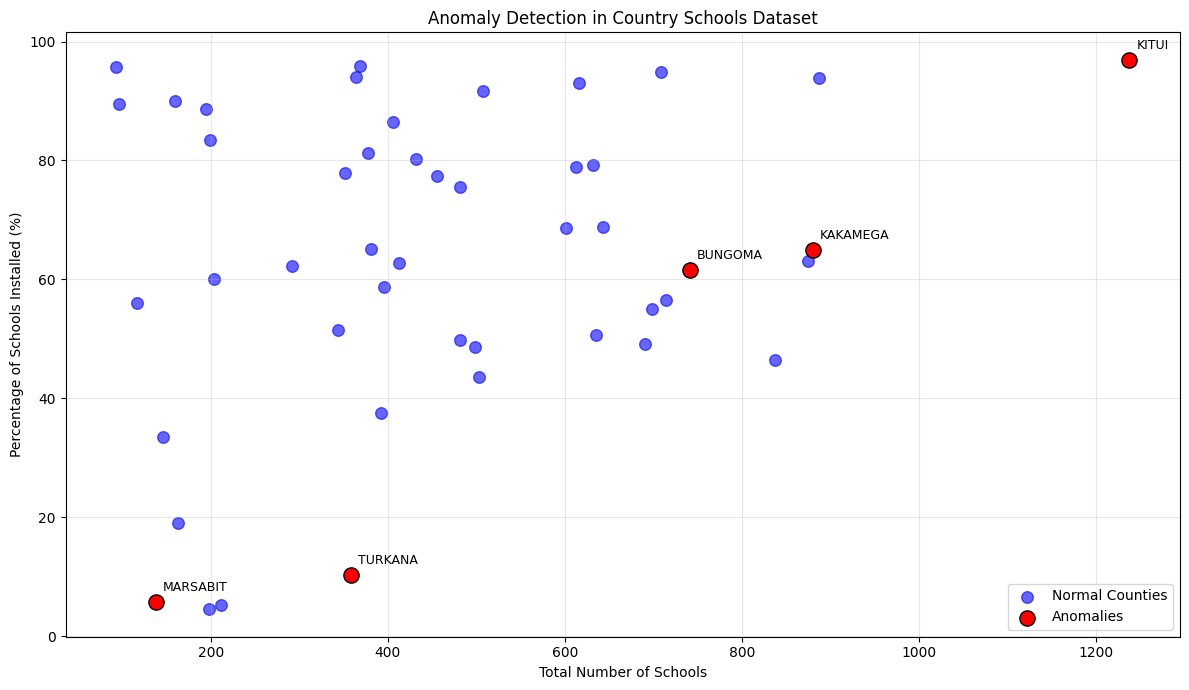

In [9]:

# Step 10: Anomaly Detection Visualization

import matplotlib.pyplot as plt

# Separate normal and anomalous counties
normal = df_clean[df_clean['Anomaly_Label'] == 1]
anomalies = df_clean[df_clean['Anomaly_Label'] == -1]

# Create the graph
plt.figure(figsize=(12, 7))

# Plot normal counties
plt.scatter(
    normal['TOTALSCHOOLS'],
    normal['PercentageInstalled'],
    color='blue',
    label='Normal Counties',
    alpha=0.6,
    s=70
)

# Plot anomalous counties
plt.scatter(
    anomalies['TOTALSCHOOLS'],
    anomalies['PercentageInstalled'],
    color='red',
    label='Anomalies',
    s=120,
    edgecolors='black'
)

# Add county names to anomalies
for _, row in anomalies.iterrows():
    plt.annotate(
        row['SNO'],
        (row['TOTALSCHOOLS'], row['PercentageInstalled']),
        xytext=(5, 8),
        textcoords='offset points',
        fontsize=9
    )

# Add graph titles and labels
plt.title('Anomaly Detection in Country Schools Dataset')
plt.xlabel('Total Number of Schools')
plt.ylabel('Percentage of Schools Installed (%)')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Display the graph
plt.show()


### Visualization and Interpretation of Anomaly Detection

A scatter plot was created to visualize the results of the Isolation Forest algorithm.

The horizontal axis represents the total number of schools, while the vertical axis represents the percentage of schools installed.

Blue points represent normal counties, and red points represent anomalous counties.

The graph shows that five counties were classified as anomalies: Kitui, Kakamega, Turkana, Marsabit, and Bungoma.

Some anomalies have very low installation percentages, while others have unusually high school or LDD counts.

The visualization helps identify unusual counties and provides a better understanding of differences in school installation characteristics across counties.

In [10]:

# Step 11: Cluster Analysis Using K-Means

# Import K-Means algorithm
from sklearn.cluster import KMeans

# Create the K-Means model with 2 clusters
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Train the model and assign clusters
df_clean['Cluster'] = kmeans.fit_predict(X_scaled)

# Display the number of counties in each cluster
print("Number of Counties in Each Cluster:")
print(df_clean['Cluster'].value_counts().sort_index())

# Display the first 10 counties with their clusters
print("\nCounty Cluster Assignments:")
display(
    df_clean[
        ['SNO', 'TOTALSCHOOLS',
         'PercentageInstalled', 'Cluster']
    ].head(10)
)

# Calculate average values for each cluster
print("\nCluster Summary:")
display(
    df_clean.groupby('Cluster')[
        ['TOTALSCHOOLS',
         'PercentageInstalled',
         'InstalledLDDs']
    ].mean().round(2)
)


Number of Counties in Each Cluster:
Cluster
0    23
1    24
Name: count, dtype: int64

County Cluster Assignments:


,SNO,TOTALSCHOOLS,PercentageInstalled,Cluster
0,TURKANA,358.0,10.34,0
1,HOMA BAY,875.0,63.09,1
2,WEST POKOT,498.0,48.59,0
3,KITUI,1238.0,96.93,1
4,TANA RIVER,159.0,89.94,0
5,TAITA TAVETA,194.0,88.66,0
6,UASIN GISHU,456.0,77.41,1
7,MIGORI,601.0,68.72,1
8,VIHIGA,378.0,81.22,1
9,NYAMIRA,406.0,86.45,1



Cluster Summary:


,TOTALSCHOOLS,PercentageInstalled,InstalledLDDs
Cluster,,,
0,287.30,50.98,5944.61
1,630.04,76.32,24453.83


### Experiment 2: Cluster Analysis Using K-Means

K-Means clustering was applied to the standardized Country Schools dataset using three selected features: TOTALSCHOOLS, PercentageInstalled, and InstalledLDDs.

Initially, the number of clusters was set to 2.

The algorithm divided the 47 counties into two groups:

- **Cluster 0:** Contains 23 counties with an average of 287.30 schools, 50.98% installation coverage, and 5,944.61 installed LDDs.
- **Cluster 1:** Contains 24 counties with an average of 630.04 schools, 76.32% installation coverage, and 24,453.83 installed LDDs.

The results show that Cluster 1 generally contains counties with larger school populations and higher installation coverage compared to Cluster 0.

K-Means successfully grouped counties according to similarities in their school installation characteristics.

However, further evaluation is needed to determine whether two clusters provide the best grouping.

In [11]:

# Step 12: Finding the Best Number of Clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Store experiment results
inertia_values = []
silhouette_scores = []

# Test cluster numbers from 2 to 8
K_values = range(2, 9)

for k in K_values:

    # Create K-Means model
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Train and predict cluster labels
    labels = model.fit_predict(X_scaled)

    # Calculate inertia
    inertia_values.append(model.inertia_)

    # Calculate silhouette score
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Create a results table
results = pd.DataFrame({
    'Number of Clusters': list(K_values),
    'Inertia': inertia_values,
    'Silhouette Score': silhouette_scores
})

# Display results
print("K-Means Evaluation Results:")
display(results.round(3))

# Identify the highest silhouette score
best_index = results['Silhouette Score'].idxmax()

print("\nBest K by Silhouette Score:")
print(results.loc[best_index, 'Number of Clusters'])

print("\nHighest Silhouette Score:")
print(round(results.loc[best_index, 'Silhouette Score'], 3))


K-Means Evaluation Results:


,Number of Clusters,Inertia,Silhouette Score
0,2,76.451,0.376
1,3,49.871,0.387
2,4,37.868,0.377
3,5,28.230,0.392
4,6,21.664,0.400
5,7,17.532,0.404
6,8,14.458,0.428



Best K by Silhouette Score:
8

Highest Silhouette Score:
0.428


### Evaluation of K-Means Clustering

To evaluate K-Means clustering, different numbers of clusters ranging from 2 to 8 were tested using the Elbow Method and Silhouette Score.

The results showed that inertia decreased as the number of clusters increased, from 76.451 at K = 2 to 14.458 at K = 8.

The highest Silhouette Score was 0.428 at K = 8, suggesting that eight clusters provided the best separation among the tested values according to this metric.

However, a higher number of clusters can create smaller groups that are more difficult to interpret. Therefore, the Elbow Method and the practical meaning of the clusters should also be considered before selecting the final number of clusters.

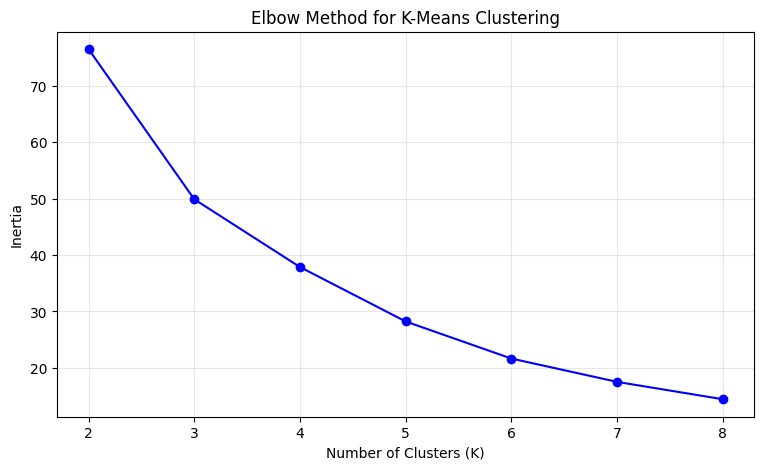

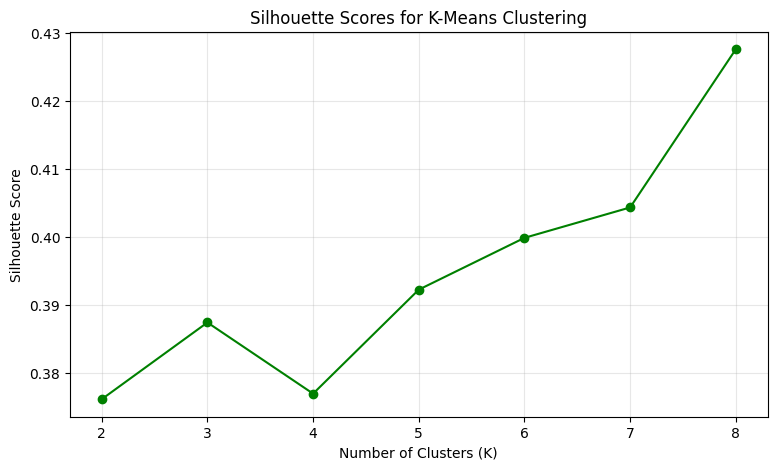

In [12]:

# Step 13: Visualizing K-Means Evaluation Results

import matplotlib.pyplot as plt

# Graph 1: Elbow Method
plt.figure(figsize=(9, 5))

plt.plot(
    list(K_values),
    inertia_values,
    marker='o',
    color='blue'
)

plt.title('Elbow Method for K-Means Clustering')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(K_values))
plt.grid(True, alpha=0.3)
plt.show()


# Graph 2: Silhouette Scores
plt.figure(figsize=(9, 5))

plt.plot(
    list(K_values),
    silhouette_scores,
    marker='o',
    color='green'
)

plt.title('Silhouette Scores for K-Means Clustering')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(K_values))
plt.grid(True, alpha=0.3)
plt.show()


### Visualization of K-Means Evaluation Results

Two graphs were generated to evaluate the performance of K-Means clustering.

**Elbow Method:** The graph shows that inertia decreases as the number of clusters increases. The reduction is larger for smaller K values and becomes more gradual as more clusters are added.

**Silhouette Score:** The graph shows the Silhouette Scores for K values ranging from 2 to 8. The highest Silhouette Score was 0.428 at K = 8.

The results suggest that K = 8 provides the strongest separation among the tested values according to the Silhouette Score. However, the final cluster selection should also consider the Elbow Method and the interpretability of the resulting groups.

In [13]:

# Step 14: Final K-Means Clustering

from sklearn.cluster import KMeans

# Select the number of clusters
best_k = 8

# Create the final K-Means model
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Train the model and assign counties to clusters
df_clean['Final_Cluster'] = final_kmeans.fit_predict(X_scaled)

# Display number of counties in each cluster
print("Number of Counties in Each Cluster:")
print(df_clean['Final_Cluster'].value_counts().sort_index())

# Calculate average values for each cluster
print("\nFinal Cluster Summary:")

cluster_summary = df_clean.groupby('Final_Cluster').agg(
    Number_of_Counties=('SNO', 'count'),
    Average_Schools=('TOTALSCHOOLS', 'mean'),
    Average_Installation=('PercentageInstalled', 'mean'),
    Average_LDDs=('InstalledLDDs', 'mean')
)

display(cluster_summary.round(2))

# Display county cluster assignments
print("\nCounty Cluster Assignments:")

display(
    df_clean[
        ['SNO', 'TOTALSCHOOLS',
         'PercentageInstalled', 'Final_Cluster']
    ].sort_values('Final_Cluster')
)


Number of Counties in Each Cluster:
Final_Cluster
0     6
1     7
2     8
3    11
4     2
5     7
6     5
7     1
Name: count, dtype: int64

Final Cluster Summary:


,Number_of_Counties,Average_Schools,Average_Installation,Average_LDDs
Final_Cluster,,,,
0,6,202.33,13.08,1785.17
1,7,401.00,84.05,17194.14
2,8,711.75,57.32,18989.00
3,11,365.27,54.18,7809.18
4,2,810.50,63.27,41541.00
5,7,628.00,87.45,28440.29
6,5,148.20,89.46,6081.80
7,1,1238.00,96.93,42162.00



County Cluster Assignments:


,SNO,TOTALSCHOOLS,PercentageInstalled,Final_Cluster
0,TURKANA,358.0,10.34,0
28,GARISSA,163.0,19.02,0
30,MANDERA,198.0,4.55,0
38,MARSABIT,138.0,5.80,0
36,WAJIR,211.0,5.21,0
46,SAMBURU,146.0,33.56,0
23,TRANS NZOIA,352.0,77.84,1
6,UASIN GISHU,456.0,77.41,1
24,KWALE,364.0,93.96,1
22,ElGEYO,369.0,95.93,1


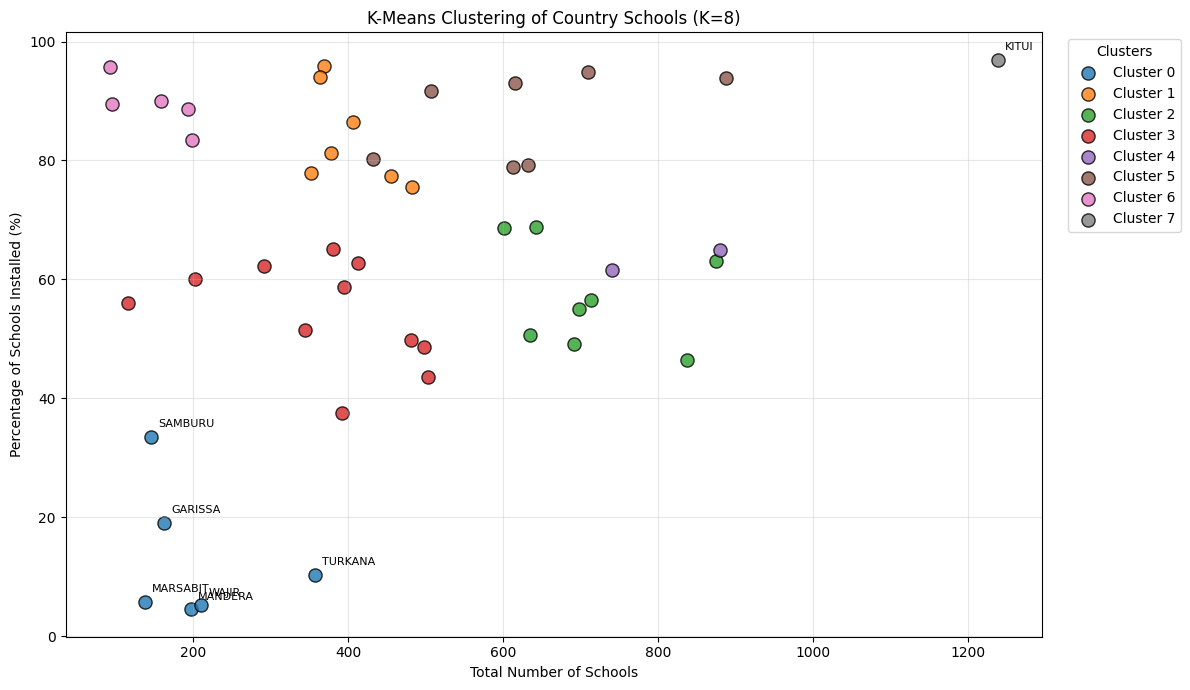

In [14]:

# Step 15: Visualize Final K-Means Clusters

import matplotlib.pyplot as plt

# Create the graph
plt.figure(figsize=(12, 7))

# Select colors for the 8 clusters
colors = plt.get_cmap('tab10')

# Plot each cluster separately
for cluster in sorted(df_clean['Final_Cluster'].unique()):

    cluster_data = df_clean[
        df_clean['Final_Cluster'] == cluster
    ]

    plt.scatter(
        cluster_data['TOTALSCHOOLS'],
        cluster_data['PercentageInstalled'],
        label=f'Cluster {cluster}',
        color=colors(int(cluster)),
        s=90,
        alpha=0.8,
        edgecolors='black'
    )

# Label counties in Cluster 0 and Cluster 7
special_counties = df_clean[
    df_clean['Final_Cluster'].isin([0, 7])
]

for _, row in special_counties.iterrows():
    plt.annotate(
        row['SNO'],
        (row['TOTALSCHOOLS'], row['PercentageInstalled']),
        xytext=(5, 7),
        textcoords='offset points',
        fontsize=8
    )

# Add graph title and axis labels
plt.title('K-Means Clustering of Country Schools (K=8)')
plt.xlabel('Total Number of Schools')
plt.ylabel('Percentage of Schools Installed (%)')

# Display legend and grid
plt.legend(title='Clusters', bbox_to_anchor=(1.02, 1),
           loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Show graph
plt.show()


### Interpretation of Final K-Means Clustering Results

The K-Means clustering algorithm was applied to the Country Schools dataset using eight clusters. The algorithm grouped 47 counties according to similarities in total schools, installation percentages, and installed LDDs.

A scatter plot was created to visualize the clustering results. The horizontal axis represents the total number of schools, while the vertical axis represents the percentage of schools installed. Different colors represent different clusters.

**Interpretation of the Results**

Cluster 0 contains six counties: Turkana, Garissa, Mandera, Marsabit, Wajir, and Samburu. These counties have the lowest average installation percentage of 13.08%, indicating relatively low school installation coverage.

Clusters 1, 5, and 6 generally contain counties with higher installation percentages. Cluster 1, for example, has an average installation percentage of 84.05%.

Clusters 2 and 3 contain counties with moderate installation coverage, while Cluster 4 contains two counties with relatively high numbers of installed LDDs.

Cluster 7 contains only Kitui, which has 1,238 schools and an installation percentage of 96.93%. This makes Kitui different from most other counties based on the selected features.

The clustering results demonstrate how K-Means can group counties with similar school installation characteristics.

**Conclusion**

K-Means successfully divided the 47 counties into eight clusters. The highest Silhouette Score among the tested values was 0.428 at K = 8, indicating moderate cluster separation.

The results show differences in school installation coverage and infrastructure across counties. Counties with particularly low installation percentages may require further investigation and attention.

However, some clusters contain very few counties, so the eight-cluster solution should be interpreted carefully.

### Final Conclusion

In this assignment, data preprocessing, anomaly detection, and cluster analysis were performed on the Country Schools dataset using Python.

During preprocessing, missing values and unnecessary records were removed, and the data was prepared for machine learning. The final dataset contained 47 counties.

Isolation Forest was used for anomaly detection and identified 5 unusual counties: Kitui, Kakamega, Turkana, Marsabit, and Bungoma.

K-Means was used for cluster analysis and divided the counties into 8 groups based on their similarities. The highest Silhouette Score was 0.428.

In conclusion, anomaly detection helped identify unusual counties, while cluster analysis helped group counties with similar characteristics. These techniques can help us better understand differences in school installation coverage across counties.